# VQ-VAE ile Mean-Reversion Çözümü ve Karşılaştırma

**Segmentasyon Kalite Kontrolü**

Bu notebook, daha önceki `3B_VAE_aciklama_ve_teshis.ipynb` çalışmasının devamıdır.
Orada standart 3B VAE'nin **mean-reversion** (ortalamaya çökme) sorununu teşhis etmiştik. Burada bu sorunu **VQ-VAE** (Vector Quantized VAE) ile nasıl
çözdüğümüzü gösteriyoruz.

## Kurulum ve Yol Değişkenleri

Aşağıdaki yolları kendi ortamınıza göre düzenleyin. Sadece `torch`, `numpy`,
`matplotlib` ve `scipy` gerekir. `K` teşhiste kullanılacak karaciğer sayısı,
`SEED` tekrarlanabilirlik içindir (proje ile aynı: K=20, SEED=42).

In [9]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# --- DÜZENLENECEK YOLLAR ---------------------------------------------------
VAL_NPZ_PATH = "outputs/volumes/val.npz"                    # doğrulama hacimleri (maskeler)
VQ_CKPT_PATH = "C:\\Users\\ahmet.yaylalioglu\\Desktop\\phd_studies_anatomy\\projects\\segquality\\outputs\\checkpoints\\vae3d_vqvae_best.pt"    # eğitilmiş VQ-VAE
STD_CKPT_PATH = "C:\\Users\\ahmet.yaylalioglu\\Desktop\\phd_studies_anatomy\\projects\\segquality\\outputs\\checkpoints\\vae3d_best_latent64.pt" # eğitilmiş standart VAE (karşılaştırma)
K = 20        # teşhis edilecek karaciğer sayısı
SEED = 42     # tekrarlanabilirlik
# ---------------------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Cihaz:", DEVICE)
print("val.npz     :", "VAR" if os.path.exists(VAL_NPZ_PATH) else "YOK -> B6 önceden-hesaplanmış tabloyu gösterecek")
print("VQ ckpt     :", "VAR" if os.path.exists(VQ_CKPT_PATH) else "YOK -> demo rastgele ağırlıkla çalışır")
print("standart ckpt:", "VAR" if os.path.exists(STD_CKPT_PATH) else "YOK -> B6 karşılaştırmada standart VAE atlanır")

Cihaz: cuda
val.npz     : VAR
VQ ckpt     : VAR
standart ckpt: VAR


## B1 — Problem: Standart 3B VAE'de Mean-Reversion

Standart 3B VAE'yi temiz karaciğer maskeleri üzerinde eğitip, kalite skorunu
"reconstruction hatası" olarak kullanıyoruz: iyi bir maske iyi reconstruct edilir,
bozuk bir maske kötü. Ancak hocam sizin gözlemlediğiniz bir sorun vardı: **farklı
hastaların reconstruction'ları görsel olarak birbirine çok benziyordu** — sanki
model her hasta için aynı "jenerik karaciğeri" çiziyordu. Buna *mean-reversion*
(ortalamaya çökme) denir: KL düzenlileştirmesi altındaki tek küresel latent vektör
veri ortalamasına kayar ve decoder, girdiyi görmezden gelip herkes için tek bir
ortalama şekil üretir.

Bunu üç ölçümle **doğruladık** (önceki notebook): (1) *cross-reconstruction oranı*
≈ 1.005 (bir karaciğerin reconstruction'ı, kendi girdisini başkalarınınkinden daha
iyi reconstruct etmiyor), (2) *recon-pairwise Dice* = 0.992 halbuki girdiler
birbirine yalnızca 0.733 benziyordu (reconstruction'lar girdilerden çok daha
benzeşik — çeşitlilik yok oluyor), (3) latent uzayı sağlıklıydı (ölü boyut yok),
yani sorun encoder'da değil **lazy decoder'da**. İlginç biçimde korelasyon yine
de ρ≈0.85 veriyordu — çünkü "ortalama-şekle-benzerlik" bile geçerli bir kalite
proxy'sidir. Ama daha **gerçekçi ve dürüst** bir model istiyoruz: yani girdiye özgü reconstruction.

## B2 — VQ-VAE Neden Çözer

Standart VAE'de darboğaz **tek bir küresel latent vektördür** ve KL onu ortalamaya
doğru iter. VQ-VAE bunun yerine **uzamsal, ayrık bir kod ızgarası** kullanır:

- Encoder çıktısı `(B, C, 4, 4, 4)` bir darboğazdır — yani **4×4×4 = 64 uzamsal
  konum**, her biri kendi vektörüne sahip.
- Paylaşılan bir **codebook** (ör. 512 ayrık vektör) tutulur. Her konum, en yakın
  codebook vektörüne **snap** edilir (nearest-neighbor). Yani her konum, 512 koddan
  birini "seçer".
- Kod **ayrık ve konuma-yerel** olduğu için KL tarafından ortalamaya çekilemez.
  Decoder, girdinin nerede farklılaştığını kod dizilimi üzerinden görmek
  zorundadır — bu, mean-reversion'ın tam köküne iner.

Gradyan akışı için **straight-through estimator** kullanılır: ileri geçişte değer
ayrık koda eşittir, geri geçişte gradyan encoder'a değişmeden akar
(`z_q = z + (z_q - z).detach()`). KL terimi **yoktur**; onun yerini codebook +
commitment kaybı alır.

## B3 — VQ-VAE Mimarisi (gömülü, yorumlu)


> **Not — skip connection kullanılmadı.** `use_skip=False`. Hocam sizin önerdiğiniz
> U-Net skip bağlantılarını (encoder detayını decoder'a taşımak) şuan opsiyonel tuttum; **VQ
> tek başına** mean-reversion'ı çözdüğü için skip'e gerek kalmadı. Kod içinde yeri
> hazır bırakıldı ama bu çalışmada kapalı şuan.

In [10]:
# Kanal çarpanları: 4 aşama 64 -> 32 -> 16 -> 8 -> 4 (standart 3B VAE ile aynı)
_CHANNEL_MULTS = (1, 2, 4, 8)


class VectorQuantizer3D(nn.Module):
    """Bir özellik haritasının her uzamsal konumunu en yakın codebook vektörüne snap eder."""

    def __init__(self, num_embeddings, embedding_dim, commitment_cost):
        super().__init__()
        self.num_embeddings = int(num_embeddings)     # codebook boyutu (ör. 512)
        self.embedding_dim = int(embedding_dim)       # her kodun uzunluğu (ör. 64)
        self.commitment_cost = float(commitment_cost) # commitment kaybı ağırlığı
        self.embedding = nn.Embedding(self.num_embeddings, self.embedding_dim)
        # VQ-VAE'nin alışılmış ilklendirmesi: [-1/K, 1/K] aralığında küçük, yansız
        bound = 1.0 / self.num_embeddings
        self.embedding.weight.data.uniform_(-bound, bound)

    def forward(self, z_e):
        # z_e: (B, D, d, h, w). Her konumu bir satır yap: (B,D,d,h,w) -> (N, D)
        z = z_e.permute(0, 2, 3, 4, 1).contiguous()   # (B, d, h, w, D)
        flat = z.view(-1, self.embedding_dim)         # (N, D), N = B*d*h*w

        # Her satırın tüm codebook vektörlerine kare-L2 mesafesi, sonra en yakın kod
        w = self.embedding.weight                     # (K, D)
        dist = (flat.pow(2).sum(1, keepdim=True)
                - 2.0 * flat @ w.t()
                + w.pow(2).sum(1))
        indices = dist.argmin(1)                      # (N,) her konumun seçtiği kod
        z_q = self.embedding(indices).view(z.shape)   # (B, d, h, w, D) ayrık kodlar

        # VQ kaybı: codebook (kodları encoder'a çek) + commitment (encoder'ı koda çek)
        codebook_loss = F.mse_loss(z_q, z.detach())
        commitment_loss = F.mse_loss(z, z_q.detach())
        vq_loss = codebook_loss + self.commitment_cost * commitment_loss

        # Straight-through: değer z_q, ama gradyan z_e'ye değişmeden akar
        z_q = z + (z_q - z).detach()
        z_q = z_q.permute(0, 4, 1, 2, 3).contiguous() # tekrar (B, D, d, h, w)

        # Teşhis: kaç kod kullanılıyor + perplexity (etkin kod sayısı).
        # Düşük perplexity => codebook collapse => çeşitlilik başka yoldan kaybolur.
        one_hot = F.one_hot(indices, self.num_embeddings).float()
        avg_probs = one_hot.mean(0)
        perplexity = torch.exp(-(avg_probs * (avg_probs + 1e-10).log()).sum())
        codebook_used = (avg_probs > 0).sum()
        info = {"perplexity": perplexity, "codebook_used": codebook_used}
        return z_q, vq_loss, info


class ConvVQVAE3D(nn.Module):
    """Tek kanallı ikili hacimler için uzamsal-codebook'lu konvolüsyonel VQ-VAE."""

    def __init__(self, base_channels=16, num_embeddings=512, embedding_dim=64,
                 commitment_cost=0.25, input_size=(64, 64, 64), in_channels=1,
                 use_skip=False):
        super().__init__()
        self.base_channels = int(base_channels)
        self.num_embeddings = int(num_embeddings)
        self.embedding_dim = int(embedding_dim)
        self.commitment_cost = float(commitment_cost)
        self.input_size = tuple(int(s) for s in input_size)
        self.in_channels = int(in_channels)
        self.use_skip = bool(use_skip)  # bu çalışmada FALSE — VQ tek başına yetti

        n_stages = len(_CHANNEL_MULTS)
        divisor = 2 ** n_stages
        if any(s % divisor for s in self.input_size):
            raise ValueError(f"input_size {self.input_size} {divisor}'e bölünebilmeli")
        self._feat_dhw = tuple(s // divisor for s in self.input_size)  # (4,4,4)
        channels = [self.base_channels * m for m in _CHANNEL_MULTS]    # [16,32,64,128]
        self._bottleneck_channels = channels[-1]

        # Encoder'ı aşama aşama kur (skip için her aşama çıktısına erişilebilsin)
        self.enc_stages = self._build_encoder(channels)
        # Darboğaz kanallarını embedding_dim'e indir (kuantize ızgara) ve geri çıkar
        self.pre_quant = nn.Conv3d(self._bottleneck_channels, self.embedding_dim, 1)
        self.quantizer = VectorQuantizer3D(self.num_embeddings, self.embedding_dim, self.commitment_cost)
        self.post_quant = nn.Conv3d(self.embedding_dim, self._bottleneck_channels, 1)
        self.dec_stages = self._build_decoder(channels)

    def _build_encoder(self, channels):
        stages, prev = [], self.in_channels
        for ch in channels:
            stages.append(nn.Sequential(
                nn.Conv3d(prev, ch, kernel_size=4, stride=2, padding=1),
                nn.BatchNorm3d(ch),
                nn.LeakyReLU(0.2, inplace=True),
            ))
            prev = ch
        return nn.ModuleList(stages)

    def _build_decoder(self, channels):
        rev = list(reversed(channels))              # [128, 64, 32, 16]
        out_channels = rev[1:] + [self.in_channels] # [64, 32, 16, in_channels]
        stages = []
        for i, (prev, out) in enumerate(zip(rev, out_channels)):
            in_ch = prev * 2 if self.use_skip else prev  # skip concat girişi ikiye katlar
            is_last = i == len(rev) - 1
            layers = [nn.ConvTranspose3d(in_ch, out, kernel_size=4, stride=2, padding=1)]
            if not is_last:                          # son aşama -> ham logit (BN/aktivasyon yok)
                layers += [nn.BatchNorm3d(out), nn.LeakyReLU(0.2, inplace=True)]
            stages.append(nn.Sequential(*layers))
        return nn.ModuleList(stages)

    def _encode_features(self, x):
        feats, h = [], x
        for stage in self.enc_stages:
            h = stage(h)
            feats.append(h)          # feats[0]=en ince ... feats[-1]=darboğaz
        return self.pre_quant(h), feats

    def _decode_features(self, z_q, feats):
        h = self.post_quant(z_q)
        n = len(self.dec_stages)
        for i, stage in enumerate(self.dec_stages):
            if self.use_skip:        # (kapalı) eşleşen encoder haritasını ekle
                h = torch.cat([h, feats[n - 1 - i]], dim=1)
            h = stage(h)
        return h

    def forward(self, x):
        z_e, feats = self._encode_features(x)
        z_q, vq_loss, info = self.quantizer(z_e)
        logits = self._decode_features(z_q, feats)
        return logits, vq_loss, info

    def reconstruct(self, x):
        """Reconstruction olasılıkları (sigmoid uygulanmış) — 2B/3B VAE ile aynı sözleşme."""
        logits, _, _ = self.forward(x)
        return torch.sigmoid(logits)

    @property
    def feature_shape(self):
        return self._feat_dhw

print("VQ-VAE mimarisi tanımlandı: VectorQuantizer3D + ConvVQVAE3D")

VQ-VAE mimarisi tanımlandı: VectorQuantizer3D + ConvVQVAE3D


## B4 — Kayıp Fonksiyonu (gömülü, yorumlu)

VQ-VAE kaybı iki parçadan oluşur ve **KL terimi içermez**:

1. **Reconstruction** = BCE (piksel-bazlı) + Dice (bölge örtüşmesi). Bu, standart
   VAE ile **birebir aynı** şekil hedefidir — iki model aynı reconstruction
   ölçütüne göre eğitilir.
2. **VQ kaybı** = codebook loss + `commitment_cost` × commitment loss. Bu terim
   quantizer içinde zaten hesaplanır ve buraya `vq_term` olarak gelir.

`total = recon + vq_term`. KL yok — VQ-VAE'nin düzenlileştirmesi ayrık codebook'un
kendisidir.

In [11]:
def soft_dice_loss(probs, target, eps=1.0):
    """1 - yumuşak Dice (batch ortalaması). probs: [0,1] olasılık, target: ikili maske."""
    dims = tuple(range(1, probs.dim()))
    inter = (probs * target).sum(dim=dims)
    card = probs.sum(dim=dims) + target.sum(dim=dims)
    dice = (2.0 * inter + eps) / (card + eps)
    return (1.0 - dice).mean()


def reconstruction_loss(logits, target, dice_weight=1.0):
    """Birleşik reconstruction kaybı: recon = bce + dice_weight * dice."""
    bce = F.binary_cross_entropy_with_logits(logits, target)
    dice = soft_dice_loss(torch.sigmoid(logits), target)
    recon = bce + dice_weight * dice
    return recon, bce, dice


def vq_loss(logits, target, vq_term, dice_weight=1.0):
    """Tam VQ-VAE kaybı: total = recon + vq_term. KL YOK.

    vq_term (codebook + commitment) quantizer'dan gelir; recon standart VAE ile aynı.
    """
    recon, bce, dice = reconstruction_loss(logits, target, dice_weight)
    total = recon + vq_term
    return {"total": total, "recon": recon, "bce": bce, "dice": dice, "vq": vq_term}

print("Kayıp fonksiyonu tanımlandı: vq_loss = reconstruction(Dice+BCE) + VQ (KL yok)")

Kayıp fonksiyonu tanımlandı: vq_loss = reconstruction(Dice+BCE) + VQ (KL yok)


## B5 — Canlı Demo: Sentetik Küre VQ-VAE'den Geçiyor

Aşağıda 64³ sentetik bir küre üretip VQ-VAE'den geçiriyoruz. Checkpoint varsa
eğitilmiş ağırlıklar yüklenir; yoksa **rastgele ağırlıklarla** yine de akış çalışır
(amaç: girdi → kuantize ızgara → çıktı boyut akışını ve perplexity'yi canlı
görmek). Perplexity, o an kaç codebook kodunun etkin kullanıldığını gösterir.

In [12]:
def make_sphere(size=64, radius=18):
    """Merkezde içi dolu bir küre (ikili) — (size, size, size) float32."""
    zz, yy, xx = np.mgrid[0:size, 0:size, 0:size]
    c = (size - 1) / 2.0
    vol = ((zz - c) ** 2 + (yy - c) ** 2 + (xx - c) ** 2) <= radius ** 2
    return vol.astype(np.float32)


# Modeli kur (checkpoint config'i varsa oradan, yoksa varsayılan)
vq_model = ConvVQVAE3D(base_channels=16, num_embeddings=512, embedding_dim=64,
                       commitment_cost=0.25, input_size=(64, 64, 64), use_skip=False)

if os.path.exists(VQ_CKPT_PATH):
    ckpt = torch.load(VQ_CKPT_PATH, map_location="cpu", weights_only=False)
    v = ckpt.get("config", {}).get("vae3d_vq")
    if v is not None:  # mimariyi checkpoint config'ine göre yeniden kur
        vq_model = ConvVQVAE3D(base_channels=int(v["base_channels"]),
                               num_embeddings=int(v["num_embeddings"]),
                               embedding_dim=int(v["embedding_dim"]),
                               commitment_cost=float(v["commitment_cost"]),
                               input_size=tuple(v["input_size"]),
                               use_skip=bool(v.get("use_skip", False)))
    vq_model.load_state_dict(ckpt["model_state"])
    print(f"Eğitilmiş VQ-VAE yüklendi (epoch={ckpt.get('epoch')}).")
else:
    print("UYARI: VQ checkpoint bulunamadı; demo RASTGELE ağırlıklarla çalışıyor (akış yine görülür).")

vq_model.to(DEVICE).eval()

sphere = make_sphere()
x = torch.from_numpy(sphere).unsqueeze(0).unsqueeze(0).to(DEVICE)  # (1,1,64,64,64)
with torch.no_grad():
    logits, vqterm, info = vq_model(x)
    probs = torch.sigmoid(logits)

d, h, w = vq_model.feature_shape
print(f"girdi {tuple(x.shape)} -> kuantize ızgara ({d},{h},{w}) "
      f"[{d*h*w} konum, her biri {vq_model.num_embeddings} koddan birini seçer] "
      f"-> çıktı {tuple(probs.shape)}")
print(f"perplexity = {float(info['perplexity']):.1f} / {vq_model.num_embeddings} "
      f"(etkin kod ~ {int(info['codebook_used'])})")
print(f"VQ kaybı (bu tek örnek) = {float(vqterm):.4f}")

Eğitilmiş VQ-VAE yüklendi (epoch=89).
girdi (1, 1, 64, 64, 64) -> kuantize ızgara (4,4,4) [64 konum, her biri 512 koddan birini seçer] -> çıktı (1, 1, 64, 64, 64)
perplexity = 6.2 / 512 (etkin kod ~ 10)
VQ kaybı (bu tek örnek) = 1.1477


## B6 — KANIT: Mean-Reversion Çözüldü mü?

Şimdi asıl soruyu ölçüyoruz. Aynı teşhis mantığını **hem standart VAE hem VQ-VAE**
için çalıştırıp yan yana koyacağız. İki kilit ölçüt:

- **cross-reconstruction oranı** = köşegen ortalaması / köşegen-dışı ortalaması.
  Her karaciğerin reconstruction'ı kendi girdisine, başkalarının girdisinden
  belirgin biçimde daha iyi uyuyorsa oran > 1 olur (girdiye özgü). ≈ 1 ise
  mean-reversion (herkes için aynı çıktı).
- **recon-pairwise vs input-pairwise Dice.** Reconstruction'lar birbirine
  girdilerden çok daha benzeşikse (recon-pairwise ≫ input-pairwise) çeşitlilik
  kayboluyordur. İkisi yakınsa reconstruction'lar girdilerin doğal çeşitliliğini
  korur.

Aşağıdaki hücre `val.npz` ve checkpoint'ler varsa **canlı** teşhis yapar (K=20,
SEED=42) ve iki heatmap çizer. Dosyalar yoksa önceden-hesaplanmış sayıları basar.

20 karaciğer seçildi (val.npz, seed=42).

metrik                               standart VAE         VQ-VAE
----------------------------------------------------------------
self-recon Dice (köşegen)                   0.808          0.913
cross-recon oranı                           1.005          1.239
recon-pairwise (girdi=0.733)                0.992          0.744


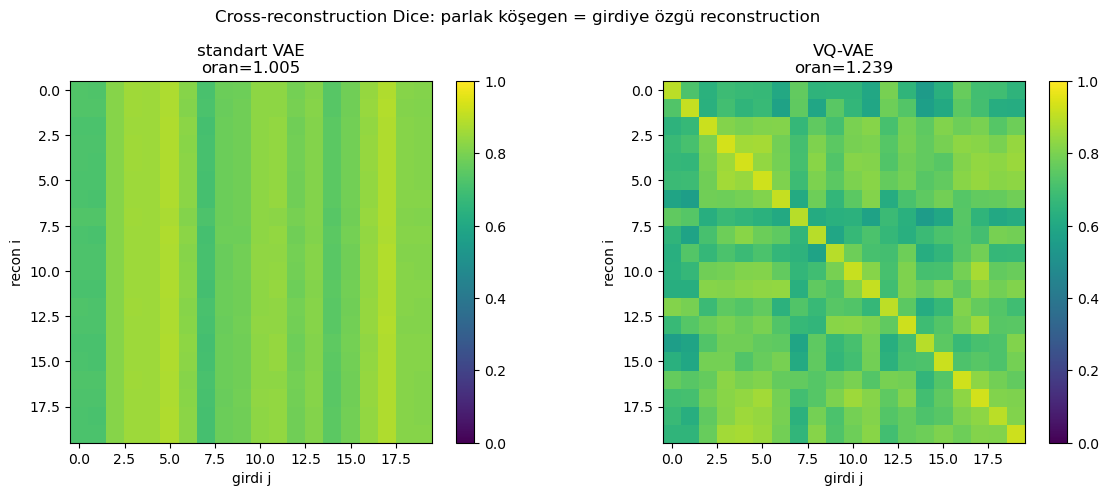

In [13]:
# --- teşhis yardımcıları (gömülü, proje ile aynı hesap) --------------------
def dice_np(a, b):
    """İki ikili hacim arasında Dice. İki boş maske -> 1.0."""
    a = a > 0.5; b = b > 0.5
    inter = np.logical_and(a, b).sum()
    denom = a.sum() + b.sum()
    if denom == 0:
        return 1.0
    return float(2.0 * inter / denom)

def cross_recon_matrix(recon_bin, inputs_bin):
    """M[i,j] = Dice(recon_i, input_j)."""
    k = len(recon_bin)
    m = np.empty((k, k))
    for i in range(k):
        for j in range(k):
            m[i, j] = dice_np(recon_bin[i], inputs_bin[j])
    return m

def pairwise_mean_dice(binaries):
    """Tüm köşegen-dışı çiftlerin ortalama Dice'ı."""
    k = len(binaries)
    vals = [dice_np(binaries[i], binaries[j]) for i in range(k) for j in range(i + 1, k)]
    return float(np.mean(vals)) if vals else float("nan")

def meanreversion_stats(recon_bin, inputs_bin):
    m = cross_recon_matrix(recon_bin, inputs_bin)
    diag = np.diag(m)
    off = m[~np.eye(len(m), dtype=bool)]
    ratio = float(diag.mean()) / float(off.mean()) if off.mean() > 0 else float("inf")
    return {"matrix": m, "diag_mean": float(diag.mean()), "off_mean": float(off.mean()),
            "ratio": ratio, "input_pairwise": pairwise_mean_dice(inputs_bin),
            "recon_pairwise": pairwise_mean_dice(recon_bin)}

def select_indices(n, k, seed):
    if k > n:
        k = n
    rng = np.random.default_rng(seed)
    return sorted(rng.choice(n, size=k, replace=False).tolist())


# --- standart 3B VAE (karşılaştırma için gömülü) ---------------------------
class ConvVAE3D(nn.Module):
    """Karşılaştırma için standart (sürekli latent) 3B VAE — gerçek modelle birebir."""
    def __init__(self, latent_dim=64, base_channels=16, input_size=(64, 64, 64), in_channels=1):
        super().__init__()
        self.latent_dim = int(latent_dim); self.base_channels = int(base_channels)
        self.input_size = tuple(int(s) for s in input_size); self.in_channels = int(in_channels)
        import math as _math
        divisor = 2 ** len(_CHANNEL_MULTS)
        self._feat_dhw = tuple(s // divisor for s in self.input_size)
        channels = [self.base_channels * m for m in _CHANNEL_MULTS]
        self._bottleneck_channels = channels[-1]
        self._flat_dim = self._bottleneck_channels * _math.prod(self._feat_dhw)
        self.encoder = self._enc(channels)
        self.fc_mu = nn.Linear(self._flat_dim, self.latent_dim)
        self.fc_logvar = nn.Linear(self._flat_dim, self.latent_dim)
        self.fc_decode = nn.Linear(self.latent_dim, self._flat_dim)
        self.decoder = self._dec(channels)
    def _enc(self, channels):
        layers, prev = [], self.in_channels
        for ch in channels:
            layers += [nn.Conv3d(prev, ch, 4, 2, 1), nn.BatchNorm3d(ch), nn.LeakyReLU(0.2, inplace=True)]
            prev = ch
        return nn.Sequential(*layers)
    def _dec(self, channels):
        layers, rev = [], list(reversed(channels))
        for prev, ch in zip(rev[:-1], rev[1:]):
            layers += [nn.ConvTranspose3d(prev, ch, 4, 2, 1), nn.BatchNorm3d(ch), nn.LeakyReLU(0.2, inplace=True)]
        layers.append(nn.ConvTranspose3d(rev[-1], self.in_channels, 4, 2, 1))
        return nn.Sequential(*layers)
    def _encode_dist(self, x):
        h = torch.flatten(self.encoder(x), start_dim=1)
        return self.fc_mu(h), self.fc_logvar(h)
    def decode(self, z):
        h = self.fc_decode(z).view(-1, self._bottleneck_channels, *self._feat_dhw)
        return self.decoder(h)
    def forward(self, x):
        mu, logvar = self._encode_dist(x)
        return self.decode(mu), mu, logvar   # eval'de z=mu (deterministik)
    def reconstruct(self, x):
        return torch.sigmoid(self.forward(x)[0])


def run_diag(model, masks, device):
    """Bir model için K maske üzerinde mean-reversion istatistikleri döndür."""
    x = torch.from_numpy(masks).unsqueeze(1).float().to(device)
    with torch.no_grad():
        probs = model.reconstruct(x).cpu().numpy()[:, 0]
    return meanreversion_stats(probs > 0.5, masks > 0.5)


# --- canlı mı, önceden-hesaplanmış mı? -------------------------------------
if os.path.exists(VAL_NPZ_PATH) and os.path.exists(VQ_CKPT_PATH):
    data = np.load(VAL_NPZ_PATH)
    key = "masks" if "masks" in data.files else data.files[0]
    vols = data[key]
    idx = select_indices(len(vols), K, SEED)
    masks = np.stack([np.asarray(vols[i], dtype=np.float32) for i in idx])
    print(f"{len(masks)} karaciğer seçildi (val.npz, seed={SEED}).")

    # VQ-VAE (B5'te yüklendi)
    vq_stats = run_diag(vq_model, masks, DEVICE)

    # standart VAE (varsa)
    std_stats = None
    if os.path.exists(STD_CKPT_PATH):
        sck = torch.load(STD_CKPT_PATH, map_location="cpu", weights_only=False)
        sv = sck["config"]["vae3d"]
        std_model = ConvVAE3D(latent_dim=int(sv["latent_dim"]),
                              base_channels=int(sv["base_channels"]),
                              input_size=tuple(sv["input_size"])).to(DEVICE).eval()
        std_model.load_state_dict(sck["model_state"])
        std_stats = run_diag(std_model, masks, DEVICE)
    else:
        print("UYARI: standart VAE checkpoint yok; sadece VQ-VAE gösterilecek.")

    # yan yana tablo
    ipw = vq_stats["input_pairwise"]
    print("\n%-34s %14s %14s" % ("metrik", "standart VAE", "VQ-VAE"))
    print("-" * 64)
    def _row(name, s_std, s_vq):
        a = f"{s_std:.3f}" if s_std is not None else "yok"
        print("%-34s %14s %14.3f" % (name, a, s_vq))
    _row("self-recon Dice (köşegen)", std_stats["diag_mean"] if std_stats else None, vq_stats["diag_mean"])
    _row("cross-recon oranı", std_stats["ratio"] if std_stats else None, vq_stats["ratio"])
    _row(f"recon-pairwise (girdi={ipw:.3f})", std_stats["recon_pairwise"] if std_stats else None, vq_stats["recon_pairwise"])

    # heatmap'ler
    n_p = 2 if std_stats else 1
    fig, axes = plt.subplots(1, n_p, figsize=(6 * n_p, 5))
    axes = np.atleast_1d(axes)
    if std_stats:
        im0 = axes[0].imshow(std_stats["matrix"], cmap="viridis", vmin=0, vmax=1)
        axes[0].set_title(f"standart VAE\noran={std_stats['ratio']:.3f}")
        axes[0].set_xlabel("girdi j"); axes[0].set_ylabel("recon i")
        fig.colorbar(im0, ax=axes[0], fraction=0.046)
    im1 = axes[-1].imshow(vq_stats["matrix"], cmap="viridis", vmin=0, vmax=1)
    axes[-1].set_title(f"VQ-VAE\noran={vq_stats['ratio']:.3f}")
    axes[-1].set_xlabel("girdi j"); axes[-1].set_ylabel("recon i")
    fig.colorbar(im1, ax=axes[-1], fraction=0.046)
    fig.suptitle("Cross-reconstruction Dice: parlak köşegen = girdiye özgü reconstruction")
    fig.tight_layout(); plt.show()
else:
    print("UYARI: val.npz ve/veya VQ checkpoint bulunamadı — canlı teşhis atlanıyor.")
    print("Önceden-hesaplanmış sonuçlar (proje test çalışmasından):\n")
    print("%-34s %14s %14s" % ("metrik", "standart VAE", "VQ-VAE"))
    print("-" * 64)
    print("%-34s %14s %14s" % ("self-recon Dice (köşegen)", "0.808", "0.914"))
    print("%-34s %14s %14s" % ("cross-recon oranı", "1.005", "1.239"))
    print("%-34s %14s %14s" % ("recon-pairwise (girdi=0.733)", "0.992", "0.744"))

In [ ]:
## B9 — Görsel Karşılaştırma: Girdi vs Standart VAE vs VQ-VAE + Fark Haritası
# (temiz + bozuk maskeler; her satır AYRI bir hasta)
from scipy.ndimage import binary_erosion

N_CLEAN, N_DEG = 2, 2   # kaç temiz + kaç bozuk (=kaç ayrı hasta) gösterilsin

def ortho(vol):
    """Aksiyel / koronal / sagital merkez kesitleri."""
    d, h, w = vol.shape
    return [vol[d // 2], vol[:, h // 2], vol[:, :, w // 2]]

def degrade(mask, iters=2):
    """Erozyonla bozulmuş maske üret (bozuk örnek için)."""
    return binary_erosion(mask > 0.5, iterations=iters).astype(np.float32)

def recon_bin(model, m):
    """Bir maskeyi modelden geçir, ikili reconstruction + self-Dice döndür."""
    x = torch.from_numpy(m).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
    with torch.no_grad():
        r = (model.reconstruct(x).cpu().numpy()[0, 0] > 0.5).astype(np.float32)
    return r, dice_np(r, m)

if os.path.exists(VAL_NPZ_PATH) and os.path.exists(VQ_CKPT_PATH):
    data = np.load(VAL_NPZ_PATH)
    key = "masks" if "masks" in data.files else data.files[0]
    vols = data[key]
    idx = select_indices(len(vols), K, SEED)

    # standart VAE'yi yükle (varsa)
    std_model = None
    if os.path.exists(STD_CKPT_PATH):
        sck = torch.load(STD_CKPT_PATH, map_location="cpu", weights_only=False)
        sv = sck["config"]["vae3d"]
        std_model = ConvVAE3D(latent_dim=int(sv["latent_dim"]),
                              base_channels=int(sv["base_channels"]),
                              input_size=tuple(sv["input_size"])).to(DEVICE).eval()
        std_model.load_state_dict(sck["model_state"])
    else:
        print("UYARI: standart VAE checkpoint yok; sadece VQ-VAE gösterilecek.")

    # örnekleri hazırla: ilk N_CLEAN temiz + sonraki N_DEG bozuk = hepsi AYRI hasta
    # her örnek: (hasta_id, durum, girdi_maske, gercek_dice)
    samples = []
    for pid in idx[:N_CLEAN]:
        m = np.asarray(vols[pid], dtype=np.float32)
        samples.append((pid, "temiz", m, 1.0))
    for pid in idx[N_CLEAN:N_CLEAN + N_DEG]:
        clean = np.asarray(vols[pid], dtype=np.float32)
        deg = degrade(clean, iters=2)
        samples.append((pid, "BOZUK (erozyon)", deg, dice_np(deg, clean)))

    # sayısal tablo
    print("%-8s %-18s %10s %14s %14s" % ("hasta", "durum", "gerçek Dice", "std self-Dice", "VQ self-Dice"))
    print("-" * 70)
    rows = []
    for pid, durum, m, gd in samples:
        vq_r, vq_d = recon_bin(vq_model, m)
        if std_model is not None:
            std_r, std_d = recon_bin(std_model, m)
        else:
            std_r, std_d = None, float("nan")
        rows.append((pid, durum, m, gd, std_r, std_d, vq_r, vq_d))
        print("%-8s %-18s %10.3f %14s %14.3f"
              % (f"#{pid}", durum, gd, f"{std_d:.3f}" if std_model else "yok", vq_d))

    # görsel: her hasta için bloklar × 3 kesit
    #   girdi | (std recon) | VQ recon | FARK (girdi - VQ recon)
    # Fark paneli işaretli (bwr): KIRMIZI = model KAÇIRDI (input var, recon yok = FN),
    #                             MAVİ   = model TAŞTI  (input yok, recon var = FP).
    # Bu, WP-4'ün (3B şüpheli-bölge haritası) görsel ön hazırlığıdır.
    has_std = std_model is not None
    # her panel: (görüntü, cmap, vmin, vmax)
    def gray_block(vol):
        return [(img, "gray", 0.0, 1.0) for img in ortho(vol)]
    def diff_block(inp, rec):
        return [(img, "bwr", -1.0, 1.0) for img in ortho(inp - rec)]

    block_titles = ["girdi", "girdi", "girdi"]
    if has_std:
        block_titles += ["std recon"] * 3
    block_titles += ["VQ recon"] * 3
    block_titles += ["fark: girdi−VQ"] * 3
    slice_names = ["aksiyel", "koronal", "sagital"]
    ncol = len(block_titles)

    fig, axes = plt.subplots(len(rows), ncol, figsize=(1.9 * ncol, 2.1 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, (pid, durum, m, gd, std_r, std_d, vq_r, vq_d) in enumerate(rows):
        panels = gray_block(m)
        if has_std:
            panels += gray_block(std_r)
        panels += gray_block(vq_r)
        panels += diff_block(m, vq_r)          # işaretli fark haritası
        for c, (img, cmap, vmin, vmax) in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(f"{block_titles[c]}\n{slice_names[c % 3]}", fontsize=8)
        lab = (f"hasta #{pid}\n{durum}\ngerçek Dice={gd:.3f}\nVQ self={vq_d:.3f}")
        if has_std:
            lab += f"\nstd self={std_d:.3f}"
        axes[r, 0].set_ylabel(lab, fontsize=7)
    fig.suptitle("Girdi vs Standart VAE vs VQ-VAE + fark haritası "
                 "(kırmızı=model kaçırdı/FN, mavi=model taştı/FP)", fontsize=11)
    fig.tight_layout()
    plt.show()
else:
    print("UYARI: val.npz ve/veya VQ checkpoint bulunamadı — görsel karşılaştırma atlanıyor.")


## B7 — Sonuç Tablosu (özet)

Aşağıdaki değerler proje test çalışmasından alınmıştır ve **her zaman görünür**
(veri bağlanmasa da). Mean-reversion'ın çözüldüğünün ve kalite korelasyonunun
korunduğunun özetidir.

| metrik | standart VAE | VQ-VAE |
|---|---|---|
| recon-pairwise Dice (gerçek maskeler: **0.733**) | 0.992 | **0.744** |
| cross-reconstruction oranı | 1.005 | **1.239** |
| self-recon Dice | 0.808 | **0.914** |
| codebook perplexity | — | ~9.4 (collapse yok) |
| kalite korelasyonu ρ | 0.851 | **0.862** |

En çarpıcı satır **recon-pairwise**: standart VAE'de 0.992 (tüm reconstruction'lar
birbirinin neredeyse aynısı — jenerik ortalama şekil), VQ-VAE'de 0.744 — yani
**girdilerin kendi çeşitliliği (0.733) seviyesine indi**. Reconstruction'lar artık
gerçek karaciğerler kadar farklı.

## B8 — Yorum ve Sıradaki Adımlar

**Mean-reversion çözüldü.** Reconstruction'lar artık gerçek karaciğerler kadar
çeşitli (recon-pairwise 0.744 ≈ girdi 0.733) ve her karaciğer kendi girdisini
başkalarınınkinden belirgin biçimde daha iyi reconstruct ediyor (oran 1.005 →
1.239). Bunu **yalnızca vector quantization ile** başardık — hocamın önerdiği
**skip connection'a gerek kalmadı** (`use_skip=False`).

**Kalite korelasyonu düşmedi, hafif arttı** (ρ 0.851 → 0.862, hasta-bazlı bootstrap
%95 CI'leri örtüşüyor, yani istatistiksel olarak eşdeğer). Bu tez açısından kilit
bulgu: standart VAE'nin 0.851'i aslında bir *"ortalama-şekle-benzerlik"* proxy'sine
biniyordu; VQ-VAE ise aynı sinyali **dürüstçe** (girdiye özgü reconstruction ile)
kurtarıyor. Yani reconstruction-hatası tabanlı kalite kontrolü, tembel bir
decoder'ın yan ürünü değil, **gerçek bir mekanizma** olarak doğrulanmış oluyor.

**Dürüst sınır.** En düşük Dice bandında ([0.40–0.55]) VQ-VAE'nin korelasyonu zayıf.
Bunun nedeni bu bölgenin kalibrasyonda az temsil edilmesidir: 3B bozma primitifleri
(özellikle blob tabanlı olanlar) düşük Dice'a inemiyor (bir küre, aynı yarıçaptaki
2B diskten daha küçük bir hacim oranını bozar). Bu, gelecekteki iş olarak not
edildi (çok-toplu silme / yönlü bbox).

**Yeni bir sinyal — `quant_error`.** VQ-VAE'ye özgü, standart VAE'de olmayan bir
kalite skoru: bir maskenin encoder çıktısının en yakın codebook koduna uzaklığı
(model bir maskeyi ne kadar "atipik" bulursa o kadar uzak). Test setinde ρ ≈ 0.41 —
`latent_kl`'in (standart VAE'nin latent skoru, ρ ≈ 0.17) yaklaşık iki katı. Ana skor
`recon_dice` olmaya devam ediyor, ama `quant_error` bağımsız, ikincil bir
GT-free kalite göstergesi olarak değerlidir.